In [1]:
# PROJECT 1:
# Zarah Dominguez
#
# Libraries ------------------------------------------------------
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.linear_model import Ridge, Lasso
   

# Data -------------------------------------------------------------
train = pd.read_csv("house-prices-advanced-regression-techniques/train.csv")
test = pd.read_csv("house-prices-advanced-regression-techniques/test.csv")

In [2]:
# Target variable
train['log_saleprice'] = np.log(train['SalePrice'])
y = train['log_saleprice']

print(train[['SalePrice', 'log_saleprice']].describe())
print(train[['SalePrice', 'log_saleprice']].skew())

           SalePrice  log_saleprice
count    1460.000000    1460.000000
mean   180921.195890      12.024051
std     79442.502883       0.399452
min     34900.000000      10.460242
25%    129975.000000      11.775097
50%    163000.000000      12.001505
75%    214000.000000      12.273731
max    755000.000000      13.534473
SalePrice        1.882876
log_saleprice    0.121335
dtype: float64


**Target transformation:** SalePrice is right-skewed (skewness = 1.88; mean 181k > median 163k). After a log transformation, the mean and median are almost equal and skewness drops to 0.12, so the distribution is close to symmetric. We model log(SalePrice) for this reason and because the competition metric is the RMSE of the log price. The standard deviation of the log price (0.40) is the RMSE of a model that always predicts the mean, so any useful model must score well below 0.40.

## 00. Exploratory Data Analysis

(1460, 82)
log_saleprice    1.000000
SalePrice        0.948374
OverallQual      0.817184
GrLivArea        0.700927
GarageCars       0.680625
GarageArea       0.650888
TotalBsmtSF      0.612134
1stFlrSF         0.596981
FullBath         0.594771
YearBuilt        0.586570
YearRemodAdd     0.565608
GarageYrBlt      0.541073
TotRmsAbvGrd     0.534422
Fireplaces       0.489449
MasVnrArea       0.430809
BsmtFinSF1       0.372023
LotFrontage      0.355878
WoodDeckSF       0.334135
OpenPorchSF      0.321053
2ndFlrSF         0.319300
HalfBath         0.313982
LotArea          0.257320
BsmtFullBath     0.236224
BsmtUnfSF        0.221985
BedroomAbvGr     0.209044
ScreenPorch      0.121208
PoolArea         0.069798
MoSold           0.057329
3SsnPorch        0.054900
BsmtFinSF2       0.004832
BsmtHalfBath    -0.005149
Id              -0.017942
MiscVal         -0.020021
OverallCond     -0.036868
YrSold          -0.037263
LowQualFinSF    -0.037963
MSSubClass      -0.073959
KitchenAbvGr    -0.147548
E

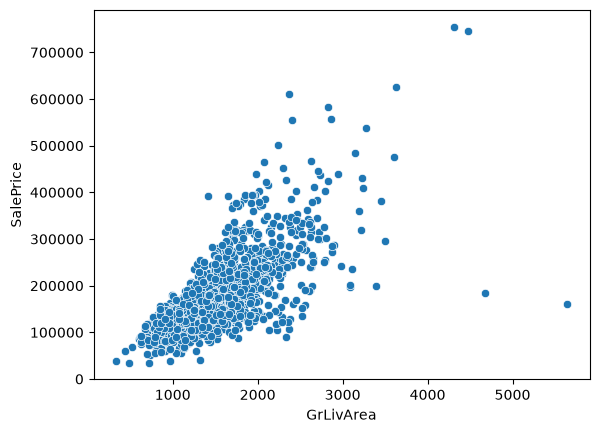

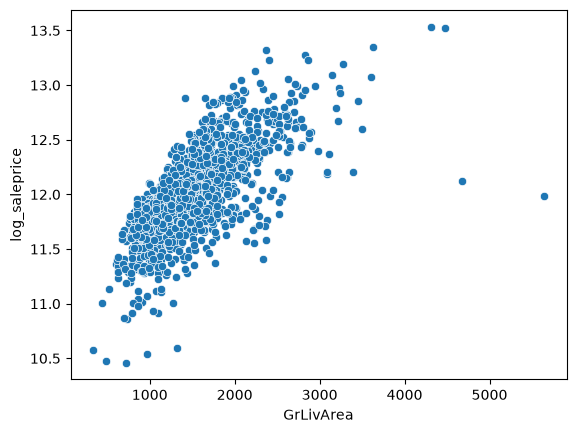

(1458, 82)
log_saleprice    1.000000
SalePrice        0.948395
OverallQual      0.821404
GrLivArea        0.725211
GarageCars       0.681033
GarageArea       0.656128
TotalBsmtSF      0.647563
1stFlrSF         0.620500
FullBath         0.595899
YearBuilt        0.587043
YearRemodAdd     0.565992
GarageYrBlt      0.541638
TotRmsAbvGrd     0.537702
Fireplaces       0.491998
MasVnrArea       0.434620
BsmtFinSF1       0.392283
LotFrontage      0.372899
WoodDeckSF       0.334250
OpenPorchSF      0.325215
2ndFlrSF         0.319953
HalfBath         0.314186
LotArea          0.260544
BsmtFullBath     0.237099
BsmtUnfSF        0.221892
BedroomAbvGr     0.209036
ScreenPorch      0.121245
PoolArea         0.074338
MoSold           0.057064
3SsnPorch        0.054914
BsmtFinSF2       0.004863
BsmtHalfBath    -0.005124
Id              -0.017774
MiscVal         -0.020012
OverallCond     -0.036821
YrSold          -0.037151
LowQualFinSF    -0.037951
MSSubClass      -0.073969
KitchenAbvGr    -0.147534
E

In [3]:
print(train.shape)   # (1460, 82)
corr_saleprice = train.corr(numeric_only=True)['log_saleprice'].sort_values(ascending=False)
print(corr_saleprice)

# The most correlated variables with log price are OverallQual (0.82), GrLivArea (0.70)
# and GarageCars (0.68). OverallQual and GarageCars are discrete (1-10 and 0-4),
# so we use a scatter of GrLivArea, the top continuous variable, to look for outliers
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice')
plt.show()

sns.scatterplot(data=train, x='GrLivArea', y='log_saleprice')
plt.show()

# In both scatters, two houses are very large but sold very cheaply, far below the 
# trend. They would distort the linear fit, so I remove them (from train only)
train = train[~((train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000))]
y = train['log_saleprice']
print(train.shape)   # (1458, 82)

# After removing the 2 outliers, the correlation of GrLivArea with log price
# rises from 0.70 to 0.73
corr_saleprice = train.corr(numeric_only=True)['log_saleprice'].sort_values(ascending=False)
print(corr_saleprice)

## 01. Handling NAs

In [4]:
# 01. Handling NAs -----------------------------
print(train.shape) # (1458, 82)
print(test.shape) # (1459, 80)
n_train = train.shape[0]
n_test = test.shape[0]

train['sample'] = "train"
test['sample'] = "test"

# To clean just once
all_data = pd.concat([train, test], ignore_index=True)
all_data = all_data.drop(columns=['SalePrice', 'log_saleprice']) # I drop the target value because I have it in y and train

missing_percentages = (all_data.isna().mean() * 100).sort_values(ascending=False)
print(missing_percentages)

(1458, 82)
(1459, 80)
PoolQC           99.691464
MiscFeature      96.400411
Alley            93.212204
Fence            80.425094
MasVnrType       60.541652
                   ...    
MiscVal           0.000000
MoSold            0.000000
YrSold            0.000000
SaleCondition     0.000000
sample            0.000000
Length: 81, dtype: float64


In [ ]:
#### PoolQC 99.69 % NAs
print(pd.crosstab(all_data['PoolQC'].isna(), all_data['PoolArea'] == 0,
            rownames=['PoolQC is NA'], colnames=['PoolArea is 0']))
all_data['dummie_pool'] = (all_data['PoolArea'] > 0).astype(int)
print(sum(all_data['dummie_pool'])/(all_data.shape[0]) * 100) # 0.41%, 12 houses of 2917. I keep the binary, and wont use PoolArea or PoolQC
all_data = all_data.drop(columns=['PoolQC', 'PoolArea'])

#### MiscFeature 96.40% NAs
print(pd.crosstab(all_data['MiscFeature'].isna(), all_data['MiscVal'] == 0,
            rownames=['MiscFeature is NA'], colnames=['MiscVal is 0']))

print(all_data['MiscVal'].describe())
print(all_data.loc[all_data['MiscVal'] > 0, 'MiscVal'].describe())

all_data['log_miscval'] = np.log1p(all_data['MiscVal']) # log(1 + x), log1p(0) = log(1) = 0. Keeping zeros
print(all_data.loc[all_data['log_miscval'] > 0, 'log_miscval'].describe())

all_data = all_data.drop(columns=['MiscVal', 'MiscFeature']) # I keep the log, and wont use MiscVal or MiscFeature 

#### Fence 80.44% | Alley 93.22% | MasVnrType 60.50% | MasVnrArea 0.78% NAs

# MasVnrType vs MasVnrArea: are NA type and zero area consistent?
print(pd.crosstab(all_data['MasVnrType'].isna(), all_data['MasVnrArea'] == 0,
                  rownames=['MasVnrType is NA'], colnames=['MasVnrArea is 0']))
print('MasVnrArea NAs:', all_data['MasVnrArea'].isna().sum())

# Houses with an area but no type (8): 3 of them have area = 1 sq ft
print(all_data.loc[all_data['MasVnrType'].isna() & (all_data['MasVnrArea'] > 0),
                   ['MasVnrType', 'MasVnrArea']])

# Alley and Fence: NA means "no alley" / "no fence", so we fill with 'None'
# MasVnrType: most NAs are the category "None" (no veneer)
# (5 houses have area > 0 but no type: type set to 'None', but their area is kept)
all_data[['Alley', 'Fence', 'MasVnrType']] = all_data[['Alley', 'Fence', 'MasVnrType']].fillna('None')

# MasVnrArea: houses with no veneer type and no area -> assume no veneer, area = 0
all_data['MasVnrArea'] = all_data['MasVnrArea'].fillna(0)
# 3 houses have MasVnrArea = 1 sq ft, which is not realistic for a veneer: treated as no veneer
all_data.loc[all_data['MasVnrArea'] == 1, 'MasVnrArea'] = 0

#### FireplaceQu 48.64% NAs
# FireplaceQu: NA matches Fireplaces = 0 exactly (crosstab), so NA means "no fireplace"
print(pd.crosstab(all_data['FireplaceQu'].isna(), all_data['Fireplaces'] == 0,
                  rownames=['FireplaceQu is NA'], colnames=['Fireplaces is 0']))
print('Fireplaces NAs:', all_data['Fireplaces'].isna().sum())

all_data[['FireplaceQu']] = all_data[['FireplaceQu']].fillna('None')

# LotFrontage: real missing values (16.6%). Median varies by neighborhood,
# so we impute with the neighborhood median, computed on TRAIN only to avoid leakage
display(all_data.groupby('Neighborhood')['LotFrontage'].agg(['mean', 'median', 'count']))

lotfront_median_by_nbhd = train.groupby('Neighborhood')['LotFrontage'].median()
lotfront_median_global  = train['LotFrontage'].median() # Fallback for neighborhoods without a median

all_data['LotFrontage'] = all_data['LotFrontage'].fillna(all_data['Neighborhood'].map(lotfront_median_by_nbhd))
all_data['LotFrontage'] = all_data['LotFrontage'].fillna(lotfront_median_global)

# Utilities dropped: all houses but one (in train) are AllPub, so it carries no information.
print(all_data['Utilities'].value_counts())
print(all_data.groupby('sample')['Utilities'].value_counts())  

all_data = all_data.drop(columns=['Utilities'])

PoolArea is 0  False  True 
PoolQC is NA               
False              9      0
True               3   2905
0.411381556393555
MiscVal is 0       False  True 
MiscFeature is NA              
False                102      3
True                   1   2811
count     2917.000000
mean        50.860816
std        567.595198
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      17000.000000
Name: MiscVal, dtype: float64
count      103.000000
mean      1440.398058
std       2681.231040
min         54.000000
25%        450.000000
50%        600.000000
75%       1200.000000
max      17000.000000
Name: MiscVal, dtype: float64
count    103.000000
mean       6.653240
std        0.937924
min        4.007333
25%        6.111467
50%        6.398595
75%        7.090910
max        9.741027
Name: log_miscval, dtype: float64
MasVnrArea is 0   False  True 
MasVnrType is NA              
False              1148      3
True                 31   1735
MasVnrArea N

,mean,median,count
Neighborhood,,,
Blmngtn,46.900000,43.0,20
Blueste,27.300000,24.0,10
BrDale,21.500000,21.0,30
BrkSide,55.789474,51.0,95
ClearCr,88.150000,80.5,20
CollgCr,71.336364,70.0,220
Crawfor,69.951807,70.0,83
Edwards,65.153409,64.5,176
Gilbert,74.207207,64.0,111


Utilities
AllPub    2914
NoSeWa       1
Name: count, dtype: int64
sample  Utilities
test    AllPub       1457
train   AllPub       1457
        NoSeWa          1
Name: count, dtype: int64


In [6]:
#### Garage columns 

garage_cols = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
               'GarageYrBlt', 'GarageArea', 'GarageCars']
print(all_data[garage_cols].isna().sum())
mask = all_data['GarageType'].notna() & all_data['GarageFinish'].isna()
display(all_data.loc[mask, garage_cols + ['sample']])

garage_cat = ['GarageFinish', 'GarageQual', 'GarageCond']

# Special cases (2 test houses with GarageType but no other garage info)
# Case 1: real garage (area 360, 1 car) but missing finish/quality/condition
# -> imputed with the mode of detached garages in TRAIN
has_garage_no_info = (all_data['GarageType'].notna()
                      & all_data['GarageFinish'].isna()
                      & all_data['GarageArea'].notna())
detchd_train = train[train['GarageType'] == 'Detchd']
for col in garage_cat:
    all_data.loc[has_garage_no_info, col] = detchd_train[col].mode()[0]

# Case 2: GarageType recorded but no area, cars or anything else -> treated as no garage
no_info_at_all = all_data['GarageType'].notna() & all_data['GarageArea'].isna()
all_data.loc[no_info_at_all, 'GarageType'] = np.nan   # it will become 'None' in the general step

# GarageYrBlt dropped: corr 0.83 with YearBuilt, equal in 76% of houses,
# no natural value for houses without a garage, and an impossible value (2207)
print(all_data['GarageYrBlt'].corr(all_data['YearBuilt']))
print((all_data['GarageYrBlt'] == all_data['YearBuilt']).mean()) # % of houses where they are the same year
print(all_data['GarageYrBlt'].describe())   

all_data = all_data.drop(columns=['GarageYrBlt'])

# Garage categorical: NA means "no garage" -> 'None'
garage_cat_all = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
all_data[garage_cat_all] = all_data[garage_cat_all].fillna('None')

# Garage numeric: no garage -> 0
all_data[['GarageArea', 'GarageCars']] = all_data[['GarageArea', 'GarageCars']].fillna(0)


GarageType      157
GarageFinish    159
GarageQual      159
GarageCond      159
GarageYrBlt     159
GarageArea        1
GarageCars        1
dtype: int64


,GarageType,GarageFinish,GarageQual,GarageCond,GarageYrBlt,GarageArea,GarageCars,sample
2124,Detchd,NaN,NaN,NaN,NaN,360.0,1.0,test
2574,Detchd,NaN,NaN,NaN,NaN,NaN,NaN,test


0.8346507056759356
0.7589989715461091
count    2758.000000
mean     1978.092096
std        25.571300
min      1895.000000
25%      1960.000000
50%      1979.000000
75%      2002.000000
max      2207.000000
Name: GarageYrBlt, dtype: float64


In [7]:
#### Basement columns
bsmt_cat = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
bsmt_num = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']

# Check: categorical NA counts differ -> some houses have a basement but missing info
print(all_data[bsmt_cat + bsmt_num].isna().sum())

# Houses WITH a basement (TotalBsmtSF > 0) but missing categorical info
has_bsmt = all_data['TotalBsmtSF'] > 0
print(all_data.loc[has_bsmt, bsmt_cat].isna().sum()) 

# Imputed with the mode of train houses that have a basement
for col in bsmt_cat:
    mode_train = train.loc[train['TotalBsmtSF'] > 0, col].mode()[0]
    all_data.loc[has_bsmt & all_data[col].isna(), col] = mode_train

# Houses WITHOUT a basement: NA means "no basement"
all_data[bsmt_cat] = all_data[bsmt_cat].fillna('None')
all_data[bsmt_num] = all_data[bsmt_num].fillna(0)


BsmtQual        81
BsmtCond        82
BsmtExposure    82
BsmtFinType1    79
BsmtFinType2    80
BsmtFinSF1       1
BsmtFinSF2       1
BsmtUnfSF        1
TotalBsmtSF      1
BsmtFullBath     2
BsmtHalfBath     2
dtype: int64
BsmtQual        2
BsmtCond        3
BsmtExposure    3
BsmtFinType1    0
BsmtFinType2    1
dtype: int64


In [8]:
#### Remaining NAs: few houses -> mode of TRAIN
remaining = all_data.columns[all_data.isna().any()].tolist()
print(remaining)

na_left = all_data[remaining].isna()
print(na_left.sum())                                # NAs per column 
print(na_left.groupby(all_data['sample']).sum())    # train vs test

# Remaining NAs: 11 values in 7 categorical columns (1-4 per column, 10 in test,
# 1 in train). All are categorical, so we impute with the mode of TRAIN to avoid
# leakage
for col in remaining:
    all_data[col] = all_data[col].fillna(train[col].mode()[0])

print(all_data.isna().sum().sum())   # 0 -> no NAs left

['MSZoning', 'Exterior1st', 'Exterior2nd', 'Electrical', 'KitchenQual', 'Functional', 'SaleType']
MSZoning       4
Exterior1st    1
Exterior2nd    1
Electrical     1
KitchenQual    1
Functional     2
SaleType       1
dtype: int64
        MSZoning  Exterior1st  Exterior2nd  Electrical  KitchenQual  \
sample                                                                
test           4            1            1           0            1   
train          0            0            0           1            0   

        Functional  SaleType  
sample                        
test             2         1  
train            0         0  
0


## 02. Categorical to numerical (encoding)

In [9]:
# Check: Mean log price and quality
qual_order = ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex']   # from worst to best
qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
             'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']

for col in qual_cols:
    price_by_qual = train.groupby(train[col].fillna('None'))['log_saleprice'].agg(['mean', 'count'])
    price_by_qual = price_by_qual.reindex(qual_order)            # order worst -> best
    price_by_qual['jump'] = price_by_qual['mean'].diff()
    print(col)
    print(price_by_qual.round(3))
    print()

# Mean log price increases with the level in the quality columns
# Negative jumps only appear in levels with very few houses (count).
# ExterCond is the exception: Gd (146 houses) is cheaper than TA, so it is
# one-hot encoded instead of ordinal

#### Ordinal encoding (8 quality columns; ExterCond goes to one-hot)
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_cols = ['ExterQual', 'BsmtQual', 'BsmtCond', 'HeatingQC',
                'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']

# Domain check: every value must be in qual_map, otherwise .map() creates NaN
for col in ordinal_cols:
    print(col, list(all_data[col].unique()))
    for value in all_data[col].unique():
        if value not in qual_map:
            print('   PROBLEM: value not in dictionary ->', value)

for col in ordinal_cols:
    all_data[col] = all_data[col].map(qual_map)

print(all_data[ordinal_cols].isna().sum())   # all 0

ExterQual
             mean  count   jump
ExterQual                      
None          NaN    NaN    NaN
Po            NaN    NaN    NaN
Fa         11.305   14.0    NaN
TA         11.838  906.0  0.533
Gd         12.311  488.0  0.473
Ex         12.792   50.0  0.481

ExterCond
             mean   count   jump
ExterCond                       
None          NaN     NaN    NaN
Po         11.245     1.0    NaN
Fa         11.455    28.0  0.210
TA         12.043  1280.0  0.588
Gd         11.969   146.0 -0.074
Ex         12.120     3.0  0.150

BsmtQual
            mean  count   jump
BsmtQual                      
None      11.530   37.0    NaN
Po           NaN    NaN    NaN
Fa        11.618   35.0    NaN
TA        11.811  649.0  0.193
Gd        12.180  618.0  0.369
Ex        12.650  119.0  0.470

BsmtCond
            mean   count   jump
BsmtCond                       
None      11.530    37.0    NaN
Po        11.066     2.0 -0.464
Fa        11.649    45.0  0.583
TA        12.043  1309.0  0.394

In [10]:
#### One-hot encoding for the remaining categorical variables
# MSSubClass is a code for the dwelling type (data_description.txt), not a quantity
all_data['MSSubClass'] = all_data['MSSubClass'].astype(str)
# Types 40 (6 houses) and 150 (1 house) are too rare -> grouped as 'Other'
all_data['MSSubClass'] = all_data['MSSubClass'].replace({'40': 'Other', '150': 'Other'})

# Keep Id and sample apart: they are not features
ids = all_data['Id']
sample = all_data['sample']
features = all_data.drop(columns=['Id', 'sample'])

# drop_first=True avoids the dummy trap (perfect collinearity) in OLS
features = pd.get_dummies(features, drop_first=True, dtype=int)

print(features.shape)
print(features.select_dtypes(include='object').shape[1])   # 0 -> no text columns left


(2917, 237)
0


## 03. Standardisation, training the model and cross-validation 
All models use a pipeline with StandardScaler, for Ridge and Lasso, the penalty depends on the size of the coefficients, so without scaling, variables measured in large units (e.g. square feet) would be penalised differently from small ones (e.g. number of bathrooms). The scaler is inside the pipeline, so in each CV (cross-validation) fold it is fitted only on the training part (no leakage). Statistics for imputation (medians, modes) are also computed on train only.

In [11]:
#### Split back into train and test
X = features[sample == 'train']
X_test = features[sample == 'test']
test_ids = ids[sample == 'test']      # For the submission file

print(X.shape, X_test.shape, y.shape)
print(X.isna().sum().sum(), X_test.isna().sum().sum())   # both 0

(1458, 237) (1459, 237) (1458,)
0 0


In [12]:
# Functions and settings -----------------------------------------

# For small datasets (N <= 10k), k-fold CV with 5-10 folds is recommended.
# With 1,458 houses we use 10 folds: each fold trains on ~1,312 houses 
# and validates on ~146
kf = KFold(n_splits = 10, shuffle = True, random_state = 1965)

def cv_rmse(model):
    scores = cross_val_score(
        model, X, y, cv=kf,
        scoring='neg_root_mean_squared_error'
    )
    # The less, the better
    # sklearn returns MINUS the RMSE, so we flip the sign
    return -scores.mean() 

# --- OLS ----------------------------------------
ols = make_pipeline(StandardScaler(), LinearRegression())
print('OLS RMSE:', cv_rmse(ols))

# --- Ridge: search alpha with CV (same folds) ---
alphas_ridge = np.logspace(-2, 3, 50)          # 0.01 ... 1000
ridge_cv = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas_ridge, cv=kf))
ridge_cv.fit(X, y)
best_alpha_ridge = ridge_cv[-1].alpha_
print('Ridge best alpha:', best_alpha_ridge)

ridge = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge))
print('Ridge RMSE:', cv_rmse(ridge))

# --- Lasso: search alpha with CV (same folds) ---
alphas_lasso = np.logspace(-4, -1, 50)         # 0.0001 ... 0.1
lasso_cv = make_pipeline(StandardScaler(), LassoCV(alphas=alphas_lasso, cv=kf, max_iter=50000))
lasso_cv.fit(X, y)
best_alpha_lasso = lasso_cv[-1].alpha_
print('Lasso best alpha:', best_alpha_lasso)

lasso = make_pipeline(StandardScaler(), Lasso(alpha=best_alpha_lasso, max_iter=50000))
print('Lasso RMSE:', cv_rmse(lasso))

OLS RMSE: 0.12152910104806063
Ridge best alpha: 193.06977288832496
Ridge RMSE: 0.11725480572692373
Lasso best alpha: 0.0029470517025518097
Lasso RMSE: 0.11306845713748723


## 04. Final model and submission_csv  

In [13]:
#### Final model: Lasso (lowest CV RMSE). Refit on ALL training data
final_model = make_pipeline(StandardScaler(), Lasso(alpha=best_alpha_lasso, max_iter=50000))
final_model.fit(X, y)

# Predict log price and go back to dollars (inverse of np.log is np.exp)
pred_test = np.exp(final_model.predict(X_test))

submission = pd.DataFrame({'Id': test_ids.values, 'SalePrice': pred_test})
submission.to_csv('zarah_submission.csv', index=False)

print(submission.shape)   # (1459, 2)
print(submission.head())

(1459, 2)
     Id      SalePrice
0  1461  116039.082513
1  1462  158700.565513
2  1463  177019.696913
3  1464  197325.212413
4  1465  199929.991407


In [14]:
#### Coefficients: OLS vs Ridge vs Lasso (all fitted on the full training set)
ols_full   = make_pipeline(StandardScaler(), LinearRegression()).fit(X, y)
ridge_full = make_pipeline(StandardScaler(), Ridge(alpha=best_alpha_ridge)).fit(X, y)
lasso_full = make_pipeline(StandardScaler(), Lasso(alpha=best_alpha_lasso, max_iter=50000)).fit(X, y)

coefs = pd.DataFrame({
    'OLS':   ols_full[-1].coef_,
    'Ridge': ridge_full[-1].coef_,
    'Lasso': lasso_full[-1].coef_
}, index=X.columns)

# Lasso zero coefficients:
print('Lasso zero coefficients:', (coefs['Lasso'] == 0).sum(), 'of', len(coefs))

# Size of the coefficients in each model
print(coefs.abs().max())

# Ranking variables by absolute Lasso coefficient
top15 = coefs.reindex(coefs['Lasso'].abs().sort_values(ascending=False).index).head(15)
display(top15.round(4))


Lasso zero coefficients: 136 of 237
OLS      0.186242
Ridge    0.049422
Lasso    0.128320
dtype: float64


,OLS,Ridge,Lasso
GrLivArea,0.0717,0.0490,0.1283
OverallQual,0.0533,0.0494,0.0758
YearBuilt,0.0534,0.0228,0.0479
OverallCond,0.0388,0.0334,0.0395
TotalBsmtSF,0.0344,0.0321,0.0355
BsmtFinSF1,0.0298,0.0257,0.0287
SaleType_New,0.0252,0.0138,0.0280
Neighborhood_Crawfor,0.0222,0.0192,0.0203
MSZoning_RL,0.1862,0.0195,0.0201
SaleCondition_Normal,0.0241,0.0210,0.0189


In [15]:
display(coefs.loc[coefs.index.str.startswith('MSZoning')].round(4))
display(coefs.loc[['GrLivArea', '1stFlrSF', '2ndFlrSF', 'TotRmsAbvGrd']].round(4))

,OLS,Ridge,Lasso
MSZoning_FV,0.0991,0.0120,0.0105
MSZoning_RH,0.0476,0.0050,0.0015
MSZoning_RL,0.1862,0.0195,0.0201
MSZoning_RM,0.1430,0.0052,-0.0000


,OLS,Ridge,Lasso
GrLivArea,0.0717,0.0490,0.1283
1stFlrSF,0.0421,0.0376,0.0063
2ndFlrSF,0.0471,0.0248,0.0000
TotRmsAbvGrd,0.0049,0.0160,0.0015


#### Coefficients: OLS vs Ridge vs Lasso

**Performance (10-fold CV RMSE):** OLS 0.1215, Ridge 0.1173 (α = 193), Lasso 0.1131 (α = 0.0029). Both regularised models beat OLS, and Lasso is the best, so I use it for the submission (Kaggle score: 0.13329).

**Lasso selects variables.** It sets 136 of the 237 coefficients to exactly zero and keeps 101. Ridge makes all coefficients smaller, but none of them becomes zero.

**OLS gives strange coefficients.** The MSZoning dummies are huge in OLS (RL = 0.186, the biggest coefficient of the model) but only 0.020 in Ridge and Lasso. The reference group (C, commercial) has very few houses, so OLS cannot estimate these dummies well. Since the goal here is prediction and not causal effects, unstable coefficients are not a problem by themselves. But with 237 correlated variables OLS also fits the noise in train, and that is why Ridge and Lasso predict better.

**Ridge spreads, Lasso chooses.** GrLivArea is almost 1stFlrSF + 2ndFlrSF, so they say the same thing. Ridge splits the weight between them (0.049 / 0.038 / 0.025). Lasso keeps only GrLivArea (0.128) and drops 2ndFlrSF (0). In the three models the total effect of size is similar.

**The top variables make sense:** living area, overall quality, year built, condition, basement size, new houses and neighborhood. For example, in Lasso, one standard deviation more of GrLivArea means about 13.7% higher price (exp(0.128) − 1).